In [1]:
%load_ext autoreload
%autoreload 2

In [24]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from src.utils import df_features_to_numpy, df_target_to_numpy
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf

# Cargo el dataset ya procesado

In [3]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [4]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [5]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    54003
HARDCOVER    22347
EBOOK        17129
UNKNOWN       4269
AUDIO         1630
OTHER          570
COMIC           52
Name: count, dtype: int64


In [6]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [7]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [9]:
def extraer_autor_principal(autores_sin_preprocesar):
    """
    autores_sin preprocesar: [{authorId, role}, {authorid, role})]
    Asumimos que el primer elemento de la lista es el autor principal (orden tipico de Goodreads)
    """
    # Buscar el primero con role vacío; si no hay, usar el primero de la lista
    for dic_autores in autores_sin_preprocesar:
        if dic_autores["role"] == "":
            return dic_autores["author_id"]
    return autores_sin_preprocesar[0]["author_id"]

df = df[df["authors"].apply(len) > 0]
df["author_id_principal"] = df["authors"].apply(extraer_autor_principal)

In [10]:
df_train, df_val, df_test = split_estratificado_autor(df, test_size=0.15, val_size=0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

Train: 71724 (71.7%)
Val: 13304 (13.3%)
Test: 14971 (15.0%)

train:
estrellas
0    0.002593
1    0.001255
2    0.009007
3    0.146548
4    0.777466
5    0.063131
Name: proportion, dtype: float64

val:
estrellas
0    0.002405
1    0.001127
2    0.008569
3    0.146121
4    0.782171
5    0.059606
Name: proportion, dtype: float64

test:
estrellas
0    0.002872
1    0.001202
2    0.009017
3    0.146416
4    0.775299
5    0.065193
Name: proportion, dtype: float64


# FIN DE TEMPORAL

## Preparacion de los datos

In [11]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK'] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## XGBoost con features basicas - Regresion

In [12]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(n_estimators = 50, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.231363    0.223143
RMSE  0.481003    0.472380
MAE   0.328708    0.324224
R²    0.079888    0.075733


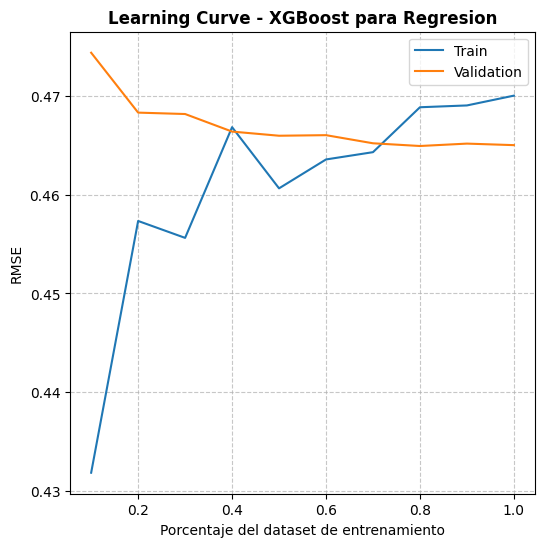

In [13]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, n_estimators = 300, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "reg:squarederror", random_state = 42)

Analizamos las feature importance:

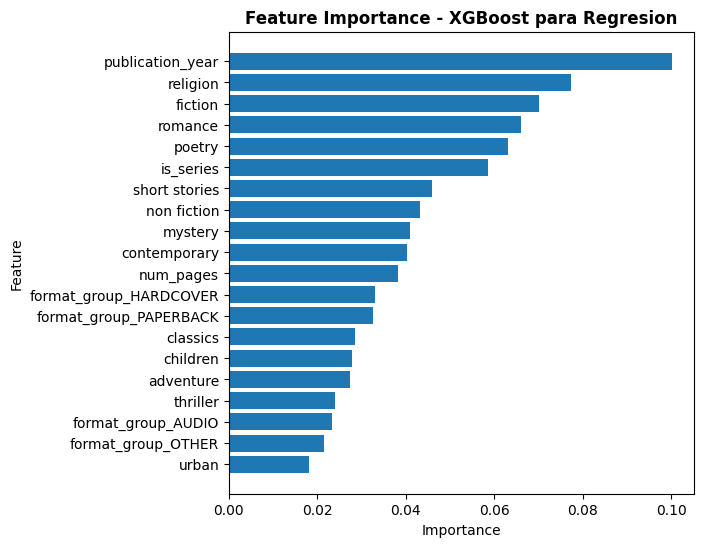

In [14]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

## XGBoost con features basicas - Clasificacion

              Train  Validation
Accuracy   0.777466    0.782171
Precision  0.129578    0.130362
Recall     0.166667    0.166667
F1         0.145800    0.146296


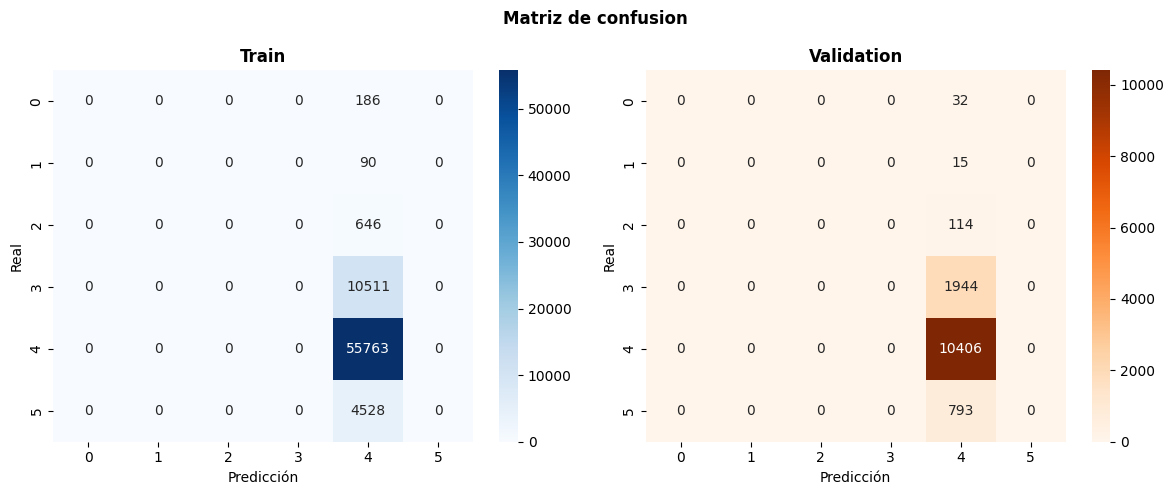

In [15]:
modeloXGBoostClasificacion = XGBClassifier(n_estimators = 50, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "multi:softmax", num_class = 5, random_state = 42) 
modeloXGBoostClasificacion.fit(X_train_scaled, y_train_clasificacion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_train_scaled))
y_pred_val_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_val_scaled))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val_clasificacion)
tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_xgboost_clasificacion)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloXGBoostClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloXGBoostClasificacion)
plot_confusion_matrix(cm_train, cm_val)

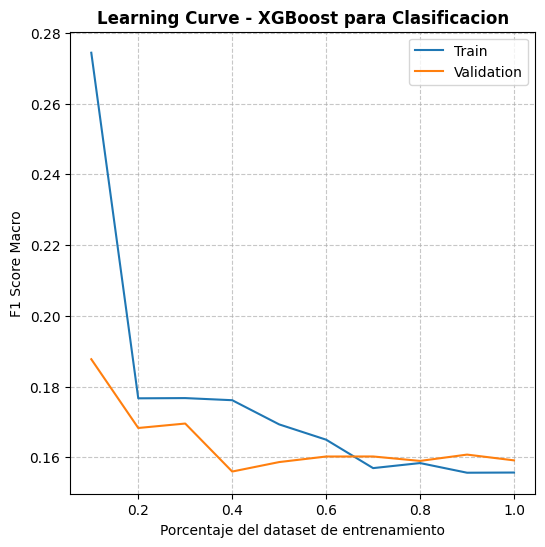

In [16]:
plot_learning_curves_xgboost_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, n_estimators = 300, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "multi:softmax", random_state = 42)

Analizamos las feature importance:

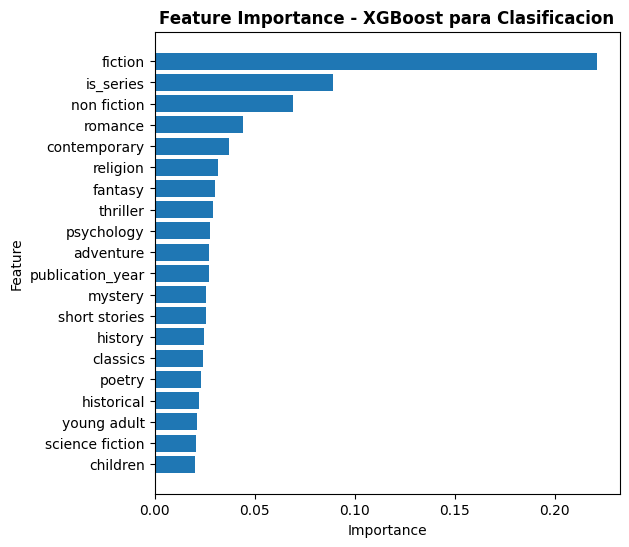

In [17]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [27]:
idx = np.random.choice(len(X_train), size = 50000, replace = False)
#TODO: con todo el dataset subir a 100mil
X_sub = X_train[idx]
y_sub_regresion = y_train_regresion[idx]
y_sub_clasificacion = y_train_clasificacion[idx]

parametros_grid_search = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
#grid search es re pesado para random forest, uso randomized search cv
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search, cv = 3, scoring="r2", n_jobs=-1, verbose=2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

#random_search = RandomizedSearchCV(estimator = RandomForestGridSearchRegresion, param_distributions = parametros_grid_search, n_iter = 30, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2, random_state = 42)
#random_search.fit(X_sub, y_sub_regresion)
#mejores_parametros = random_search.best_params_
#print(f"Mejores parametros: {mejores_parametros}")
#print(f"Mejor R² CV: {random_search.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor R² CV: 0.11174317154632045


In [28]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.188237    0.214411
RMSE  0.433863    0.463046
MAE   0.283510    0.314441
R²    0.251397    0.111899


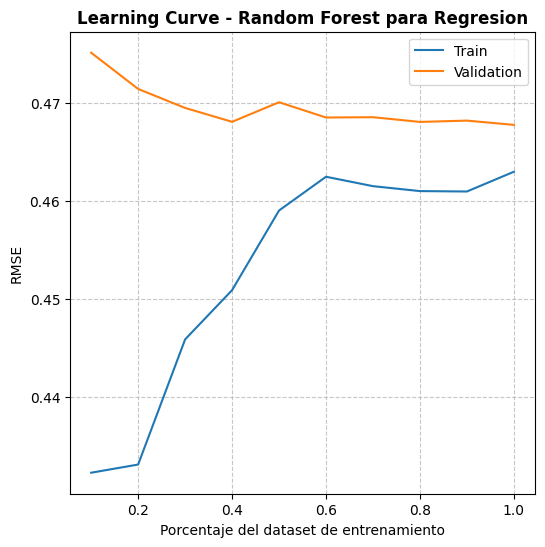

In [29]:
plot_learning_curves_randomforest_regression(X_train, y_train_regresion, X_val, y_val_regresion, 100, 10)

Analizamos la feature importance:

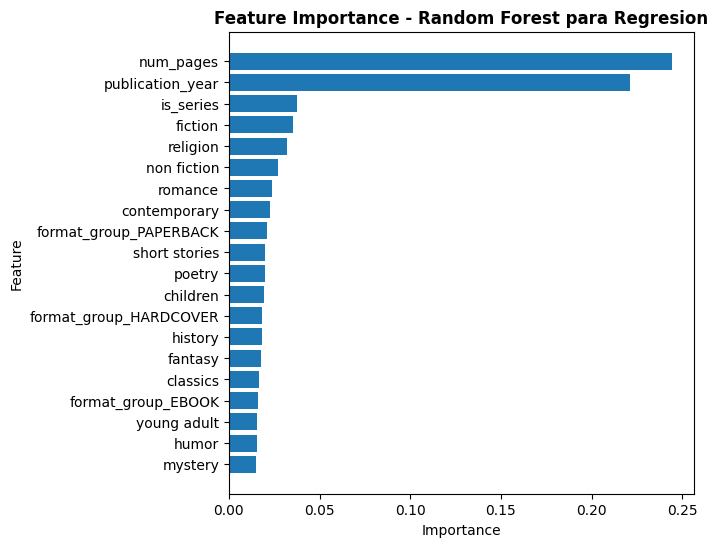

In [30]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

## Random Forest con features basicas - Clasificacion

In [32]:
RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42)

#uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
grid.fit(X_sub, y_sub_clasificacion)

mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor F1 CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Mejor F1 CV: 0.1651599806548396


              Train  Validation
Accuracy   0.840123    0.780818
Precision  0.966905    0.255701
Recall     0.277806    0.171721
F1         0.330916    0.158012


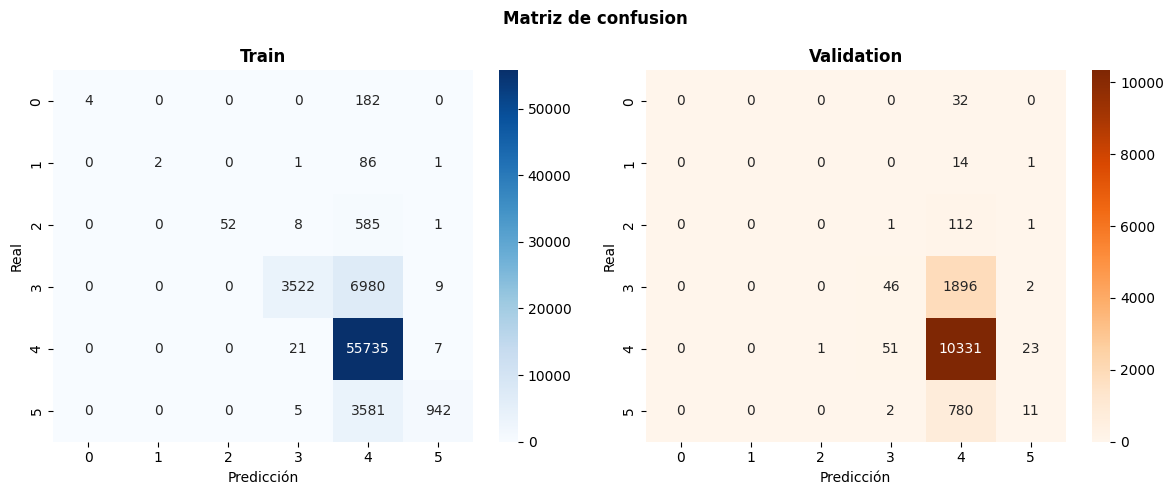

In [33]:
modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42)
modeloRandomForestClasificacion.fit(X_train, y_train_clasificacion)

y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train))
y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val_clasificacion)
tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_rf_clasificacion)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloRandomForestClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloRandomForestClasificacion)
plot_confusion_matrix(cm_train, cm_val)

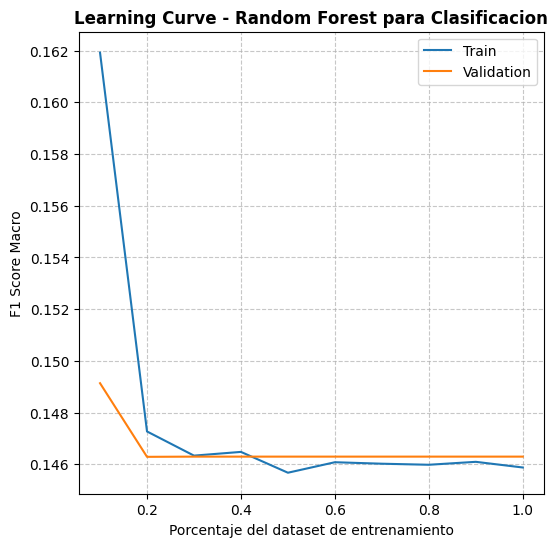

In [34]:
plot_learning_curves_randomforest_classification(X_train, y_train_clasificacion, X_val, y_val_clasificacion, 100, 10)

Analizamos la feature importance:

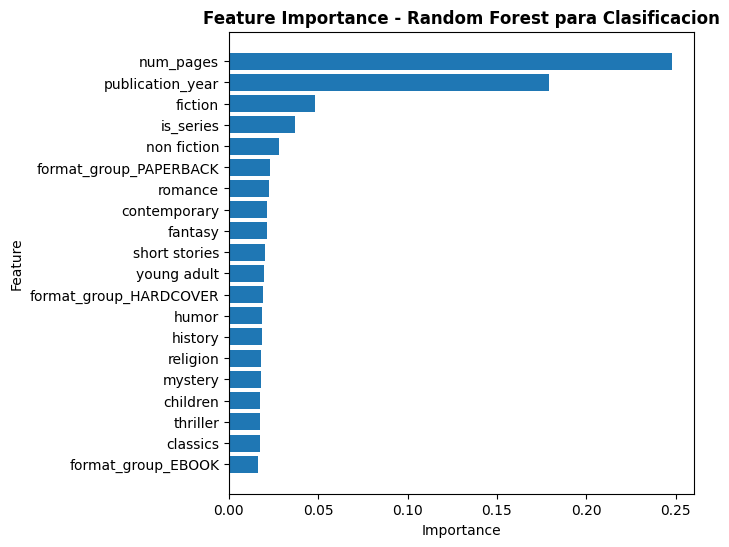

In [35]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")